In [303]:
using LowLevelFEM, LinearAlgebra

In [304]:
openGeometry("U-section.geo")
openPreProcessor()

In [305]:
mat = Material("section")
P = Field([mat], type=:ScalarField, dim=2, fieldName=:φ)

A = ∫(P, "section", (x,y,z)->1)

xc = ∫(P, "section", (x,y,z)->x) / A
yc = ∫(P, "section", (x,y,z)->y) / A
zc = ∫(P, "section", (x,y,z)->z) / A;

Ix = ∫(P, "section", (x,y,z)->(y - yc)^2)
Iy = ∫(P, "section", (x,y,z)->(x - xc)^2)

K = ∫(Grad(P) ⋅ Grad(P))
f = ∫(P ⋅ 2)

bc = BoundaryCondition("perimeter", φ=0)

ψ = solveField(Symmetric(K), f, support=[bc])

Ic = 2 * ∫(P, "section", ψ)

7681.2656411215185

A két segédmező gyenge alakja:
\[
\begin{aligned}
\int_A \nabla v\cdot\nabla\psi_x\,dA
&=\int_A v\frac{x}{I_y}\,dA
+\int_A\nabla v\cdot\boldsymbol d\,dA,\\
\int_A \nabla v\cdot\nabla\psi_y\,dA
&=\int_A v\frac{y}{I_x}\,dA
+\int_A\nabla v\cdot\boldsymbol h\,dA.
\end{aligned}
\]
A ν-tól függő, ismert polinomiális vektormezők és az összeállítás:



Mindkettő két fizikai komponenst tartalmaz: $\tau_{zx}$ és $\tau_{zy}$; a harmadik komponens nulla.

Az energiaazonosság egységnyi nyíróerő esetén:
$$
\boxed{\displaystyle
\kappa_x=\frac{1}{A\int_A|\boldsymbol\tau_x|^2\,dA},
\qquad
\kappa_y=\frac{1}{A\int_A|\boldsymbol\tau_y|^2\,dA}.}
$$
Ezt a négyzetes kifejezés felbontásával, közvetlenül az összeállított mátrixokkal is kiértékelhetjük:

In [306]:
x = scalarField(P, "section", (x,y,z)->x - xc)
y = scalarField(P, "section", (x,y,z)->y - yc)

ν = 0.3
c = ν / (2 * (1 + ν))

d1 =  c / (2Iy) * (x*x - y*y)
d2 =  c / Iy * x*y

h1 =  c / Ix * x*y
h2 = -c / (2Ix) * (x*x - y*y)

K = ∫(Grad(P) ⋅ Grad(P))
M = ∫(P ⋅ P)

qx = ∫(Grad(P) ⋅ [d1, d2])
qy = ∫(Grad(P) ⋅ [h1, h2])

fx = ∫(P ⋅ (x/Iy)) + qx
fy = ∫(P ⋅ (y/Ix)) + qy

bc = BoundaryCondition("reference", φ=0)

ψx = solveField(Symmetric(K), fx, support=[bc])
ψy = solveField(Symmetric(K), fy, support=[bc])

τx = ∇(ψx) - VectorField([d1, d2, 0*d1])
τy = ∇(ψy) - VectorField([h1, h2, 0*h1])

showElementResults(τx, name="Shear stress, Vx=1", visible=false)
showElementResults(τy, name="Shear stress, Vy=1", visible=false)

Jx = ψx'*K*ψx - 2dot(ψx.a, qx.a) + d1'*M*d1 + d2'*M*d2
Jy = ψy'*K*ψy - 2dot(ψy.a, qy.a) + h1'*M*h1 + h2'*M*h2

κx = 1 / (A * Jx)
κy = 1 / (A * Jy)

#Asx = κx * A
#Asy = κy * A

# Shear center from the existing unit Vy auxiliary solution.
qrot = ∫(Grad(P) ⋅ [-y, x])
xT = xc #+ dot(ψy.a, qrot.a) - (x'*M*h2 - y'*M*h1)

14.342105263157821

In [307]:
openGeometry("U-beam_as_beam.geo")
openPreProcessor()

## Fields and materials

Each beam segment is associated with a `Material` object. Two unknown fields are introduced:

- `U`: the two-component translational displacement field,
- `Φ`: the scalar rotation field.

The rotation field is created with `reducedOrder=true`, so it is solved in a one-order-lower continuous Lagrange space while assembly and storage remain associated with the original mesh.


In [308]:
mat = Material("beam")
U = Field([mat], type=:VectorField, dim=3, fieldName=:u, rhsName=:f)
Φ = Field([mat], type=:VectorField, dim=3, fieldName=:φ, rhsName=:m, reducedOrder=true);

In [309]:
t = tangentVector(U, "beam")
nξ, nη = normalVectors(U, "beam");


In [310]:
t = [t[1], t[2], t[3]]
nξ = [nξ[1], nξ[2], nξ[3]]
nη = [nη[1], nη[2], nη[3]];

## Timoshenko beam kinematics

The generalized beam strain vector is

$$
\boldsymbol{\varepsilon}_b=
\begin{bmatrix}
\varepsilon\\
\gamma\\
\kappa_b
\end{bmatrix},
$$

with axial strain

$$
\varepsilon=\mathbf{t}^T(\nabla\mathbf{u})\mathbf{t},
$$

shear strain

$$
\gamma=\mathbf{n}^T(\nabla\mathbf{u})\mathbf{t}-\varphi,
$$

and curvature

$$
\kappa_b=\nabla\varphi\cdot\mathbf{t}.
$$

The matrices `Au`, `Aφ`, and `Gφ` map the LowLevelFEM operator output to these generalized strain components.


In [311]:
# ------------------------------------------------------------------
# Generalized Timoshenko beam strain
#
# ε = tᵀ ∇u t
# γ = nᵀ ∇u t - φ
# κ = ∇φ ⋅ t
# ------------------------------------------------------------------

Au = vcat(kron(nξ,t)',
          kron(nη,t)',
          kron(t,t)',
          zeros(3,9)
          )

Aφ = vcat(zeros(3,9),
          kron(nξ,t)',
          kron(nη,t)',
          kron(t,t)'
          )

Gφ = vcat(-nη',
          nξ',
          zeros(4,3)
          )

Bu = Au ⋅ Grad(U)

Bφ = Aφ ⋅ Grad(Φ) + Gφ ⋅ Φ;

In [312]:
#d = 1
E = mat.E
G = mat.μ
Iξ = Ix
Iη = Iy
#κ = κy

225051.77875243637

In [313]:
e = xc - xT

S = Matrix{Float64}(I, 6, 6)
S[2,6] = 0#-e

0

In [314]:
Du = [κx*G*A 0 0
      0 κy*G*A 0
      0  0  E*A]

Dφ = [E*Iξ 0 0
      0 E*Iη 0
      0  0  G*Ic]

D = cat(Du, Dφ, dims=(1,2))

6×6 Matrix{Float64}:
 2.36841e7  0.0        0.0    0.0         0.0         0.0
 0.0        3.12559e7  0.0    0.0         0.0         0.0
 0.0        0.0        1.9e8  0.0         0.0         0.0
 0.0        0.0        0.0    2.86594e11  0.0         0.0
 0.0        0.0        0.0    0.0         4.50104e10  0.0
 0.0        0.0        0.0    0.0         0.0         5.90867e8

In [315]:
B = Bu + Bφ
K = ∫(B' ⋅ S'⋅ D ⋅ S ⋅ B, Γ="beam");
K[:,:]

1206×1206 SparseArrays.SparseMatrixCSC{Float64, Int64} with 7399 stored entries:
⎡⠻⣦⡀⠀⠀⠀⠀⠀⠀⠀⠳⣄⠀⠀⠀⠀⠀⠀⠀⠈⠳⣄⠀⠀⠀⠀⠀⠀⠀⠈⠳⣄⠀⠀⠀⠀⠀⠀⠀⠈⎤
⎢⠀⠈⠻⣦⡀⠀⠀⠀⠀⠀⠀⠈⠳⣄⠀⠀⠀⠀⠀⠀⠀⠈⠳⣄⠀⠀⠀⠀⠀⠀⠀⠈⢳⣄⠀⠀⠀⠀⠀⠀⎥
⎢⠀⠀⠀⠈⠻⣦⡀⠀⠀⠀⠀⠀⠀⠈⠳⣄⠀⠀⠀⠀⠀⠀⠀⠈⠳⣄⠀⠀⠀⠀⠀⠀⠀⠙⠷⣄⠀⠀⠀⠀⎥
⎢⠀⠀⠀⠀⠀⠈⠻⣦⡀⠀⠀⠀⠀⠀⠀⠈⠳⣄⠀⠀⠀⠀⠀⠀⠀⠈⠳⣄⠀⠀⠀⠀⠀⠀⠀⠈⠳⣄⠀⠀⎥
⎢⠀⠀⠀⠀⠀⠀⠀⠈⠻⣦⡀⠀⠀⠀⠀⠀⠀⠈⠳⣄⠀⠀⠀⠀⠀⠀⠀⠈⠳⣄⠀⠀⠀⠀⠀⠀⠀⠈⢳⣄⎥
⎢⠙⢦⡀⠀⠀⠀⠀⠀⠀⠈⠑⢄⠀⠀⠀⠀⠀⠀⠀⠈⠻⣦⡀⠀⠀⠀⠀⠀⠀⠈⠠⣄⠀⠀⠀⠀⠀⠀⠀⠉⎥
⎢⠀⠀⠙⢦⡀⠀⠀⠀⠀⠀⠀⠀⠑⢄⠀⠀⠀⠀⠀⠀⠀⠈⠻⣄⠀⠀⠀⠀⠀⠀⠀⠀⠀⡀⠀⠀⠀⠀⠀⠀⎥
⎢⠀⠀⠀⠀⠙⢦⡀⠀⠀⠀⠀⠀⠀⠀⠑⢄⠀⠀⠀⠀⠀⠀⠀⠈⠳⣤⡀⠀⠀⠀⠀⠀⠀⠈⠳⣄⠀⠀⠀⠀⎥
⎢⠀⠀⠀⠀⠀⠀⠙⢦⡀⠀⠀⠀⠀⠀⠀⠀⠑⢄⠀⠀⠀⠀⠀⠀⠀⠈⠻⣦⡀⠀⠀⠀⠀⠀⠀⠈⠣⣄⠀⠀⎥
⎢⡀⠀⠀⠀⠀⠀⠀⠀⠙⢦⡀⠀⠀⠀⠀⠀⠀⠀⠑⢄⡀⠀⠀⠀⠀⠀⠀⠈⠻⣄⠀⠀⠀⠀⠀⠀⠀⠀⠳⣄⎥
⎢⠙⢦⡀⠀⠀⠀⠀⠀⠀⠀⠻⣦⡀⠀⠀⠀⠀⠀⠀⠈⠻⣦⡀⠀⠀⠀⠀⠀⠀⠈⠳⣄⠀⠀⠀⠀⠀⠀⠀⠈⎥
⎢⠀⠀⠙⢦⡀⠀⠀⠀⠀⠀⠀⠈⠛⢦⡀⠀⠀⠀⠀⠀⠀⠈⠻⣦⡀⠀⠀⠀⠀⠀⠀⠈⠳⣄⠀⠀⠀⠀⠀⠀⎥
⎢⠀⠀⠀⠀⠙⢦⡀⠀⠀⠀⠀⠀⠀⠀⠙⣦⡀⠀⠀⠀⠀⠀⠀⠈⠻⣦⡀⠀⠀⠀⠀⠀⠀⠈⠳⣄⠀⠀⠀⠀⎥
⎢⠀⠀⠀⠀⠀⠀⠙⢦⡀⠀⠀⠀⠀⠀⠀⠈⠻⣦⡀⠀⠀⠀⠀⠀⠀⠈⠻⣦⡀⠀⠀⠀⠀⠀⠀⠈⠳⣄⠀⠀⎥
⎢⡀⠀⠀⠀⠀⠀⠀⠀⠙⢦⡀⠀⠀⠀⠀⠀⠀⠈⠛⢦⡀⠀⠀⠀⠀⠀⠀⠈⠻⣦⠀⠀⠀⠀⠀⠀⠀⠈⠳⣄⎥
⎢⠙⢦⡀⠀⠀⠀⠀⠀⠀⠀⠘⢦⠀⠀⠀⠀⠀⠀⠀⠀⠙⢦⡀⠀⠀⠀⠀⠀⠀⠀⠑⢄⠀⠀⠀⠀⠀⠀⠀⠀⎥
⎢⠀⠀⠙⢶⣄⠀⠀⠀⠀⠀⠀⠀⠀⠀⡀⠀⠀⠀⠀⠀⠀⠀⠙⢦⡀⠀⠀⠀⠀⠀⠀⠀⠑⢄⠀⠀⠀⠀⠀⠀⎥
⎢⠀⠀⠀⠀⠙⢧⡀⠀⠀⠀⠀⠀⠀⠀⠙⢤⠀⠀⠀⠀⠀⠀⠀⠀⠙⢦⡀⠀⠀⠀⠀⠀⠀⠀⠑⢄⠀⠀⠀⠀⎥
⎢⠀⠀⠀⠀⠀⠀⠙⢦⡀⠀⠀⠀⠀⠀⠀⠀⠉⢦⠀⠀⠀⠀⠀⠀⠀⠀⠙⢦⡀⠀⠀⠀⠀⠀⠀⠀⠑⢄⠀⠀⎥
⎣⡀⠀⠀⠀⠀⠀⠀⠀⠙⢶⡄⠀⠀⠀⠀⠀⠀⠀⠙⢦⡀⠀⠀⠀⠀⠀⠀⠀⠙⢦⠀⠀⠀⠀⠀⠀⠀⠀⠑⢄⎦

In [316]:
bc1 = BoundaryCondition("support", field=U, ux=0, uy=0, uz=0)
bc2 = BoundaryCondition("support", field=Φ, φx=0, φy=0, φz=0)

BoundaryCondition("support", Problem("U-beam_as_beam", :VectorField, 3, 3, Material[Material("beam", :Hooke, 200000.0, 0.3, 115384.61538461536, 76923.07692307692, 166666.66666666663, 7.85e-9, 45.0, 4.2e8, 1.2e-5, 1.0e-7, 0.1, 1.0)], 1.0, 201, LowLevelFEM.Geometry("", "", 0, 0, nothing, nothing, nothing, nothing), :φ, :m, true, :lagrange, LowLevelFEM.ApproximationData(sparse([1, 304, 2, 305, 3, 306, 7, 304, 307, 8  …  602, 303, 600, 603, 4, 601, 5, 602, 6, 603], [1, 1, 2, 2, 3, 3, 4, 4, 4, 5  …  299, 300, 300, 300, 301, 301, 302, 302, 303, 303], [1.0, 0.5, 1.0, 0.5, 1.0, 0.5, 1.0, 0.5, 0.5, 1.0  …  0.5, 1.0, 0.5, 0.5, 1.0, 0.5, 1.0, 0.5, 1.0, 0.5], 603, 303), sparse([1, 2, 3, 301, 302, 303, 4, 5, 6, 7  …  291, 292, 293, 294, 295, 296, 297, 298, 299, 300], [1, 2, 3, 4, 5, 6, 7, 8, 9, 10  …  294, 295, 296, 297, 298, 299, 300, 301, 302, 303], [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], 303, 603), nothing)), Dict{Symbol, Union{Fun

In [317]:
fu = ∫(U ⋅ [0,1000,0], Γ="load")
fφ = ∫(Φ ⋅ [0,0,0], Γ="load")

F = SystemVector([fu, fφ]);

In [318]:
u, φ = solveField(K, F, support=[bc1,bc2]);

In [319]:
showDoFResults(fu, name="force", visible=true)
showDoFResults(fφ, name="moment", visible=true)
showDoFResults(u, name="u", factor=10, visible=true);

## Recovery of beam resultants

For post-processing, the local in-plane normal vector is stored as a `VectorField`. The generalized beam strains are then recovered from the solved displacement and rotation fields.


In [320]:
#n = VectorField([nx, ny, 0]);

The displacement field is expanded to the 3D vector representation used by the general gradient and vector-algebra routines. The rotation field is converted to an elementwise field before its gradient is evaluated.

The recovered quantities are

$$
\varepsilon=\mathbf{t}\cdot\left((\nabla\mathbf{u})\mathbf{t}\right),
$$

$$
\gamma=\mathbf{n}\cdot\left((\nabla\mathbf{u})\mathbf{t}\right)-\varphi,
$$

and

$$
\kappa_b=\nabla\varphi\cdot\mathbf{t}.
$$

The corresponding internal forces are

$$
N=EA\varepsilon,
\qquad
T=\kappa_sGA\gamma,
\qquad
M=EI_z\kappa_b.
$$


In [321]:
#u = expandTo3D(u)
φ = nodesToElements(φ)

t = tangentVector(U, "beam")
nξ, nη = normalVectors(U, "beam")

g = ∇(u)

ε = t ⋅ (g * t)
γξ = nξ ⋅ (g * t) - φ ⋅ nη
γη = nη ⋅ (g * t) + φ ⋅ nξ

κξ = nξ ⋅ (∇(φ) * t)
κη = nη ⋅ (∇(φ) * t)
ϑ = t ⋅ (∇(φ) * t)

N = E * A * ε
Tξ = κx * G * A * γξ
Tη = κy * G * A * γη

Mhξ = E * Iξ * κξ
Mhη = E * Iη * κη
Mc_T = G * Ic * ϑ
Mc = Mc_T - e * Tη

elementwise ScalarField
[[0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0;;]  …  [0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0;;], [0.0; 0.0; 0.0;;]]

In [322]:
showElementResults(t, name="t")
showElementResults(nξ, name="nξ")
showElementResults(nη, name="nη")

5

In [323]:
Tξ0, plotTξ = plotOnBeam("beam", Tξ, name="Tξ graph", plot=true)
Tη0, plotTη = plotOnBeam("beam", Tη, name="Tη graph", plot=true)
N0, plotN = plotOnBeam("beam", N, name="N graph", plot=true)
Mhξ0, plotMhξ = plotOnBeam("beam", Mhξ, name="Mhξ graph", plot=true)
Mhη0, plotMhη = plotOnBeam("beam", Mhη, name="Mhη graph", plot=true)
Mc0, plotMc = plotOnBeam("beam", Mc, name="Mc graph", plot=true);

The returned diagram coordinates can also be processed with an external plotting package if a publication-style figure is preferred.


In [324]:
using Plots

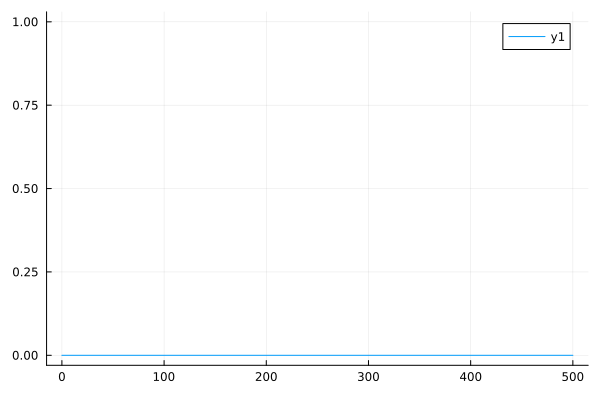

In [325]:
plot(plotN)

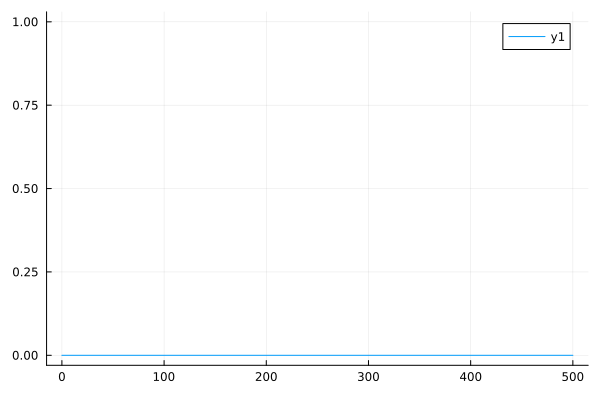

In [326]:
plot(plotTξ)

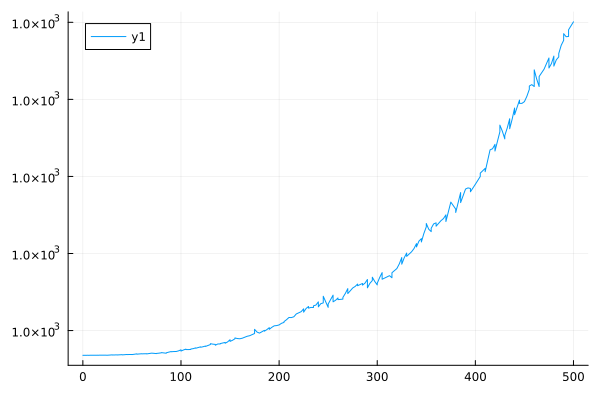

In [327]:
plot(plotTη)

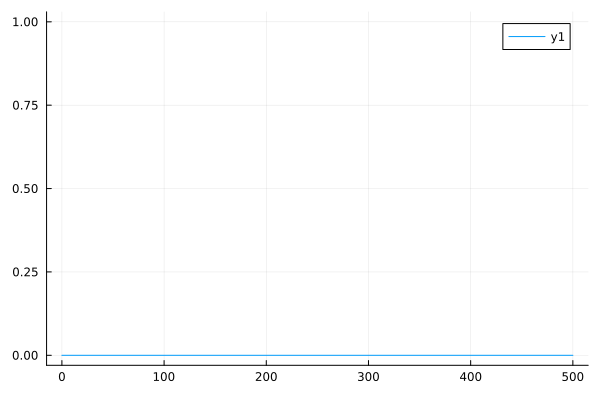

In [328]:
plot(plotMc)

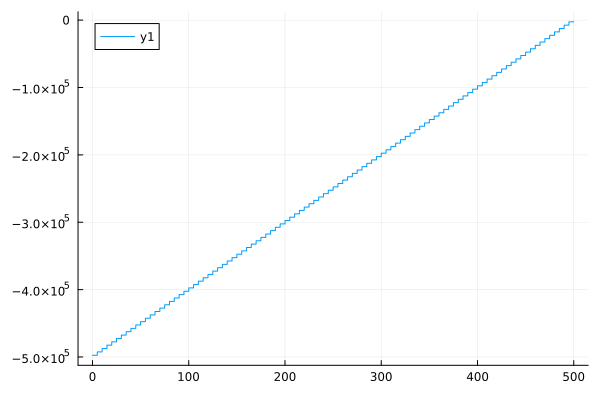

In [329]:
plot(plotMhξ)

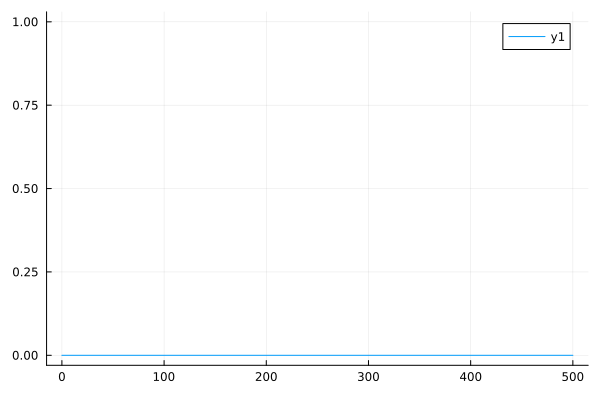

In [330]:
plot(plotMhη)

In [331]:
probe(u, "load")

3-element Vector{Float64}:
 0.0
 0.1613792155
 0.0

In [332]:
probe(φ, "load")

3-element Vector{Float64}:
 -0.0004361576
  0.0
  0.0

In [333]:
openPostProcessor()